In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, precision_recall_curve, f1_score)

df = pd.read_csv("../data/clean_churn.csv")
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_bin
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,0,No,No,45,No,No,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [7]:
# Drop the text target so it doesn't leak into the features
X = df.drop(columns=["Churn", "Churn_bin"])
y = df["Churn_bin"]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))   # both ~0.265

(5634, 19) (1409, 19)
0.265 0.265


In [8]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    results[name] = scores.mean()
    print(f"{name}: ROC-AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: ROC-AUC = 0.846 (+/- 0.012)
Random Forest: ROC-AUC = 0.829 (+/- 0.012)


In [10]:
from xgboost import XGBClassifier

scale = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                    scale_pos_weight=scale, eval_metric="logloss", random_state=42)
pipe = Pipeline([("prep", preprocess), ("model", xgb)])
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"XGBoost: ROC-AUC = {scores.mean():.3f}")

XGBoost: ROC-AUC = 0.843


In [11]:
# Example with logistic regression; swap in whichever scored best
pipe = Pipeline([("prep", preprocess),
                 ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])

param_grid = {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l2"]}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Best params: {'model__C': 10, 'model__penalty': 'l2'}
Best CV ROC-AUC: 0.846


c:\Users\uthuni Fernando\OneDrive\Desktop\AI_DS\Year_2\sem_1\ML\telco_churn\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Test ROC-AUC: 0.841


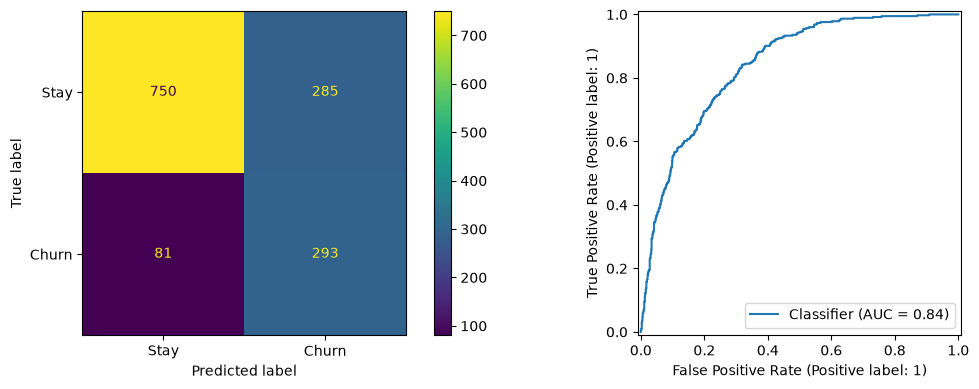

In [12]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Stay", "Churn"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stay", "Churn"], ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
plt.tight_layout()
plt.savefig("../images/model_evaluation.png", bbox_inches="tight")
plt.show()

In [13]:
prec, rec, thr = precision_recall_curve(y_test, y_proba)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1s[:-1])]
print("Best threshold for F1:", round(best_thr, 2))

y_pred_tuned = (y_proba >= best_thr).astype(int)
print(classification_report(y_test, y_pred_tuned, target_names=["Stay", "Churn"]))

Best threshold for F1: 0.57
              precision    recall  f1-score   support

        Stay       0.89      0.77      0.83      1035
       Churn       0.54      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



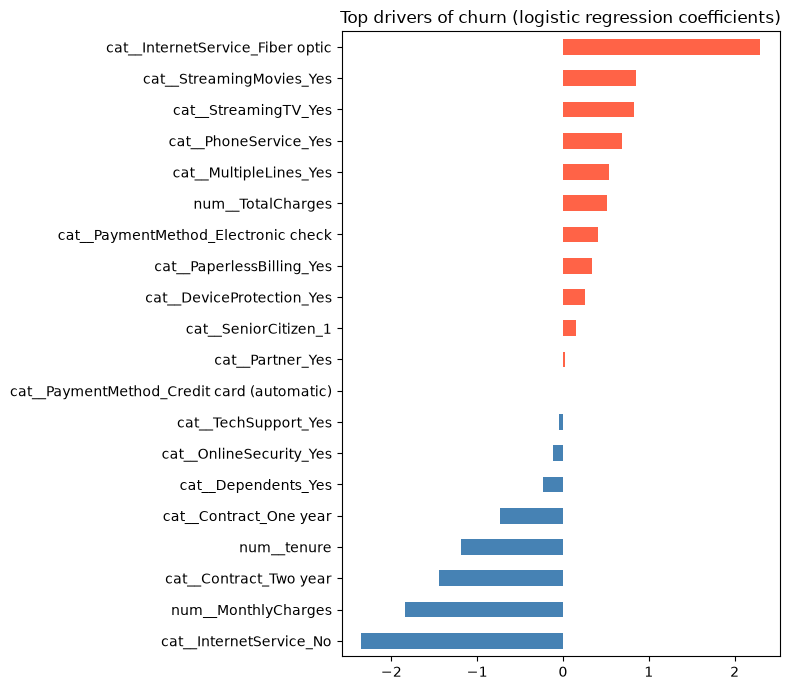

In [14]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
coefs = best_model.named_steps["model"].coef_[0]

imp = pd.Series(coefs, index=feature_names).sort_values()
top = pd.concat([imp.head(10), imp.tail(10)])

plt.figure(figsize=(8, 7))
top.plot(kind="barh", color=np.where(top > 0, "tomato", "steelblue"))
plt.title("Top drivers of churn (logistic regression coefficients)")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", bbox_inches="tight")
plt.show()

In [ ]:
from xgboost import XGBClassifier

scale = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                    scale_pos_weight=scale, eval_metric="logloss", random_state=42)
pipe = Pipeline([("prep", preprocess), ("model", xgb)])
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"XGBoost: ROC-AUC = {scores.mean():.3f}")

XGBoost: ROC-AUC = 0.843


In [15]:
import os
os.makedirs("../results", exist_ok=True)
joblib.dump(best_model, "../results/churn_model.joblib")

['../results/churn_model.joblib']